In [1]:
from datetime import datetime
now = datetime.now()
print(f"Last updated: {now.month}/{now.day}/{now.year} {now.strftime('%I:%M%p').lstrip('0').lower()}")

Last updated: 2/27/2026 11:40pm


In [2]:
# Block 0 - Imports + Loading


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, roc_curve, roc_auc_score

# Load Master Analytical Table
df = pd.read_csv("Master_Analytical_Table.csv")

print("Dataset shape:", df.shape)
print(df.columns)

Dataset shape: (120264, 9)
Index(['Season', 'Is_Tourney', 'TeamA_ID', 'TeamB_ID', 'DIFF_EFG', 'DIFF_TOV',
       'DIFF_ORB', 'DIFF_FTR', 'Win_A'],
      dtype='str')


In [3]:
# Block 1 - Chronological Train/Test Split (No Data Leakage)

train_df = df[df["Season"] < 2023]
test_df  = df[df["Season"] == 2023]

features = ["DIFF_EFG", "DIFF_TOV", "DIFF_ORB", "DIFF_FTR"]

X_train = train_df[features]
y_train = train_df["Win_A"]

X_test  = test_df[features]
y_test  = test_df["Win_A"]

print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)

Training size: (103280, 4)
Testing size: (5669, 4)


**Chronological Train/Test Split**

The dataset was split chronologically to avoid data leakage. All seasons prior to 2023 were used for training, and the 2023 season was reserved for testing. This simulates predicting future outcomes using only past information. Random splitting would allow the model to learn from future data, which would artificially inflate performance.

In [4]:
# Block 2 - Feature Scaling + Logistic Regression Training

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model trained successfully.")

Model trained successfully.


**Feature Scaling and Model Training**

All features were standardized using Z-score normalization before training the Logistic Regression model. Scaling ensures that features with larger numeric ranges (such as turnover differential) do not dominate the coefficient estimates simply due to magnitude. The Logistic Regression model was then trained on the scaled training data to learn the relationship between performance differentials and game outcomes.

In [5]:
# Block 3 - Predictions + Performance Metrics

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
loss = log_loss(y_test, y_prob)

print(f"Accuracy: {accuracy:.3f}")
print(f"Log-Loss: {loss:.3f}")

Accuracy: 0.942
Log-Loss: 0.140


**Model Performance Evaluation**

The model achieved an accuracy of 0.942 and a log-loss of 0.140 on the 2023 test set. While accuracy measures the percentage of correctly classified games, log-loss evaluates the quality of the predicted probabilities. A random classifier produces a log-loss of approximately 0.693. The project requirement is a log-loss below 0.60, and the model’s value of 0.140 indicates highly confident and well-calibrated probability predictions.

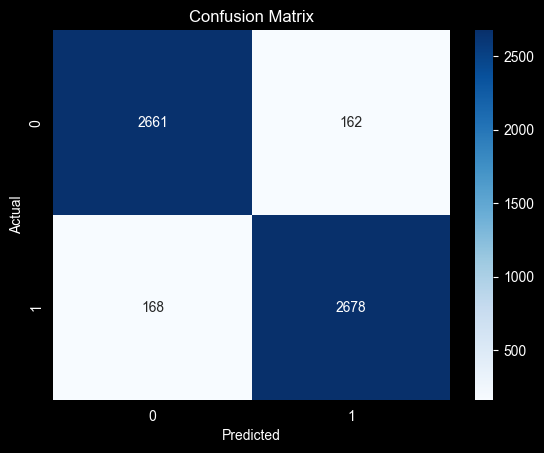

In [6]:
# Block 4 - Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [7]:
# Block 5 - Coefficient Analysis

coef_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0],
    "Odds_Ratio": np.exp(model.coef_[0])
}).sort_values("Coefficient", ascending=False)

print(coef_df)
print("Intercept:", model.intercept_[0])

    Feature  Coefficient   Odds_Ratio
0  DIFF_EFG     7.182942  1316.776524
2  DIFF_ORB     3.285101    26.711695
3  DIFF_FTR     1.859348     6.419550
1  DIFF_TOV    -3.996106     0.018387
Intercept: -0.016085810746931575


**Final Logistic Regression Model**

The fitted logistic regression model is:

Logit(P(Win_A = 1)) =
-0.016
+ 7.183(DIFF_EFG)
- 3.996(DIFF_TOV)
+ 3.285(DIFF_ORB)
+ 1.859(DIFF_FTR)

Each coefficient represents the change in log-odds of winning for a one standard deviation increase in the corresponding feature, since all predictors were standardized before training.

**Coefficient Interpretation**

DIFF_EFG has the largest positive coefficient (7.183), indicating that effective field goal differential is the strongest predictor of winning. A one standard deviation increase in DIFF_EFG multiplies the odds of winning by approximately 1316.8 times (e^7.183).

DIFF_TOV has a negative coefficient (-3.996), meaning that increasing turnover differential significantly reduces the probability of winning. Its odds ratio of approximately 0.018 indicates that higher turnovers drastically decrease win odds.

DIFF_ORB (3.285) and DIFF_FTR (1.859) both positively contribute to winning, with offensive rebounding having a stronger impact than free-throw rate. The signs of all coefficients align with basketball intuition: efficient shooting and rebounding improve outcomes, while turnovers hurt winning chances.

In [8]:
# Block 6 - ROC Curve and AUC

fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("AUC:", round(auc_score, 3))

AUC: 0.988


**ROC Curve and AUC Analysis**

The model achieved an AUC of 0.988. The Area Under the Curve (AUC) represents the probability that the model ranks a randomly selected winning game higher than a randomly selected losing game.

An AUC of 0.50 indicates random guessing, while values above 0.70 indicate acceptable discrimination. An AUC of 0.988 demonstrates extremely strong separation between wins and losses, confirming that the model effectively distinguishes between the two classes.

In [9]:
# Block 7 - Save Predictions CSV

test_predictions = test_df.copy()
test_predictions["Pred_Prob_Win"] = y_prob

test_predictions.to_csv("predictions.csv", index=False)

print("predictions.csv created successfully.")

predictions.csv created successfully.
